(1750, 47)


,family,proc_pid,file,urls,type,name,path,program,info,positives,...,regkey_opened,file_created,wmi_query,dll_loaded,regkey_written,file_read,apistats,errors,action,log
0,E,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,38,0,1,4073
1,G,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,7,0,1,19
2,E,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,8,0,1,17
3,L,0,0,0,0,0,0,0,0,1,...,0,1,0,7,0,0,28,0,1,18
4,G,0,0,0,0,0,0,0,0,1,...,27,0,0,6,0,0,33,0,1,18


Features: (1750, 46)
Target: (1750,)
Training: (1400, 46)
Testing: (350, 46)
Random Forest training completed.
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Classification Report:
              precision    recall  f1-score   support

           E       1.00      1.00      1.00       153
           G       1.00      1.00      1.00       164
           L       1.00      1.00      1.00        33

    accuracy                           1.00       350
   macro avg       1.00      1.00      1.00       350
weighted avg       1.00      1.00      1.00       350



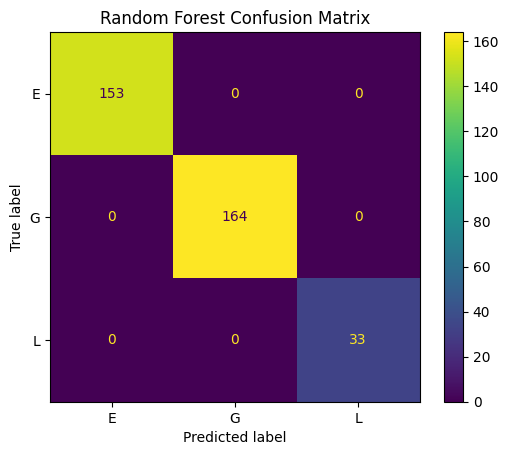

{'model': 'Random Forest', 'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1_score': 1.0}
Feature importance:
             feature  importance
            filetype    0.098843
         pe_res_name    0.090947
            apistats    0.075958
                 dll    0.072455
        file_created    0.054017
           file_read    0.051845
           arguments    0.046787
            category    0.041725
          dll_loaded    0.039810
                 api    0.033443
         pe_sec_name    0.029851
             entropy    0.029481
directory_enumerated    0.024599
         regkey_read    0.021942
           sign_name    0.021028
         description    0.019945
                 log    0.018793
        command_line    0.015897
        process_path    0.015294
    beh_command_line    0.014831
ACTION:
action
1    1421
0     329
Name: count, dtype: int64

FILETYPE:
filetype
1     299
3     223
0     191
11    173
17    128
10     97
5      87
9      77
26     50
2      50
8      50
21

In [17]:
import pandas as pd

df = pd.read_csv("../data/processed/cleaned_dataset.csv")

print(df.shape)
display(df.head())

X = df.drop(columns=["family"])
y = df["family"]

print("Features:", X.shape)
print("Target:", y.shape)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X_train, y_train)

print("Random Forest training completed.")

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = rf.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall   :", recall_score(y_test, y_pred, average="weighted"))
print("F1 Score :", f1_score(y_test, y_pred, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["E", "G", "L"]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

import json

results = {
    "model": "Random Forest",
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, average="weighted"),
    "recall": recall_score(y_test, y_pred, average="weighted"),
    "f1_score": f1_score(y_test, y_pred, average="weighted")
}

with open("../results_rf.json", "w") as f:
    json.dump(results, f, indent=4)

print(results)

print("Feature importance:")

importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

print(importance.head(20).to_string(index=False))

print("ACTION:")
print(df["action"].value_counts())

print("\nFILETYPE:")
print(df["filetype"].value_counts())

print("\nCATEGORY:")
print(df["category"].value_counts())

print("\nPROGRAM:")

print(df["program"].value_counts().head(20))

for col in X.columns:
    groups = df.groupby("family")[col].mean()
    if groups.nunique() > 1:
        print(f"\n{col}")
        print(groups)
        
        
important_features = [
    "filetype",
    "pe_res_name",
    "category",
    "pe_sec_name",
    "log",
    "action"
]

for col in important_features:
    print("\n==============================")
    print(col)
    print("==============================")
    print(df.groupby("family")[col].describe())
    
    